# Slide 11: Hermite projections of a Gaussian (and the slide-12 table)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). Pure numpy, no GK data. The exact Gaussian $e^{-\theta^2/2\sigma^2}$ and its
orthogonal projection onto the first $N$ Hermite functions $h_n(\theta/W)$ for three $(S, N)$, $S = \sigma/W$ (the talk's notation) (code from Fusion_PhD
`results/hermite_theory/t4_t5_talk.py`). Labels give only $S$ and $N$ (user: "don't state the error").

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# One style for every talk figure (identical in every notebook of this folder; Fusion_PhD-qp5.32). Each PNG fills the right-hand
# ~1060 x 800 px box of a 1920 x 1080 slide, so every figure is 10.6 x 8.0 in at 200 dpi and is saved at exactly that size
# (no bbox_inches="tight"): every PNG is scaled by the same factor on its slide, so text is the same size on every slide.
talk_style = {"figure.figsize": (10.6, 8.0), "savefig.dpi": 200, "savefig.bbox": "standard", "figure.constrained_layout.use": True,
              "font.size": 18, "axes.labelsize": 22, "axes.titlesize": 22, "figure.titlesize": 22,
              "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18, "lines.linewidth": 2.5, "lines.marker": "",
              "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}
plt.rcParams.update(talk_style)
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
from math import comb

theta = np.linspace(-40, 40, 40001)          # theta/sigma; trapezoid on a Gaussian-decaying integrand is spectrally accurate
dtheta = theta[1] - theta[0]


def hermite_functions(order_count, y):
    functions = np.zeros((order_count, len(y)))
    functions[0] = np.pi ** -0.25 * np.exp(-y ** 2 / 2)
    if order_count > 1:
        functions[1] = np.sqrt(2) * y * functions[0]
    for n in range(2, order_count):
        functions[n] = np.sqrt(2 / n) * y * functions[n - 1] - np.sqrt((n - 1) / n) * functions[n - 2]
    return functions


def project(width, n_basis):
    # projection of exp(-theta^2/2) (sigma = 1) onto the first n_basis Hermite functions of width `width`
    basis = hermite_functions(n_basis, theta / width)
    target = np.exp(-theta ** 2 / 2)
    fit = (basis @ target * dtheta) @ basis / width     # L2-orthonormal functions are basis / sqrt(width)
    return target, fit, np.sqrt(np.sum((target - fit) ** 2) / np.sum(target ** 2))

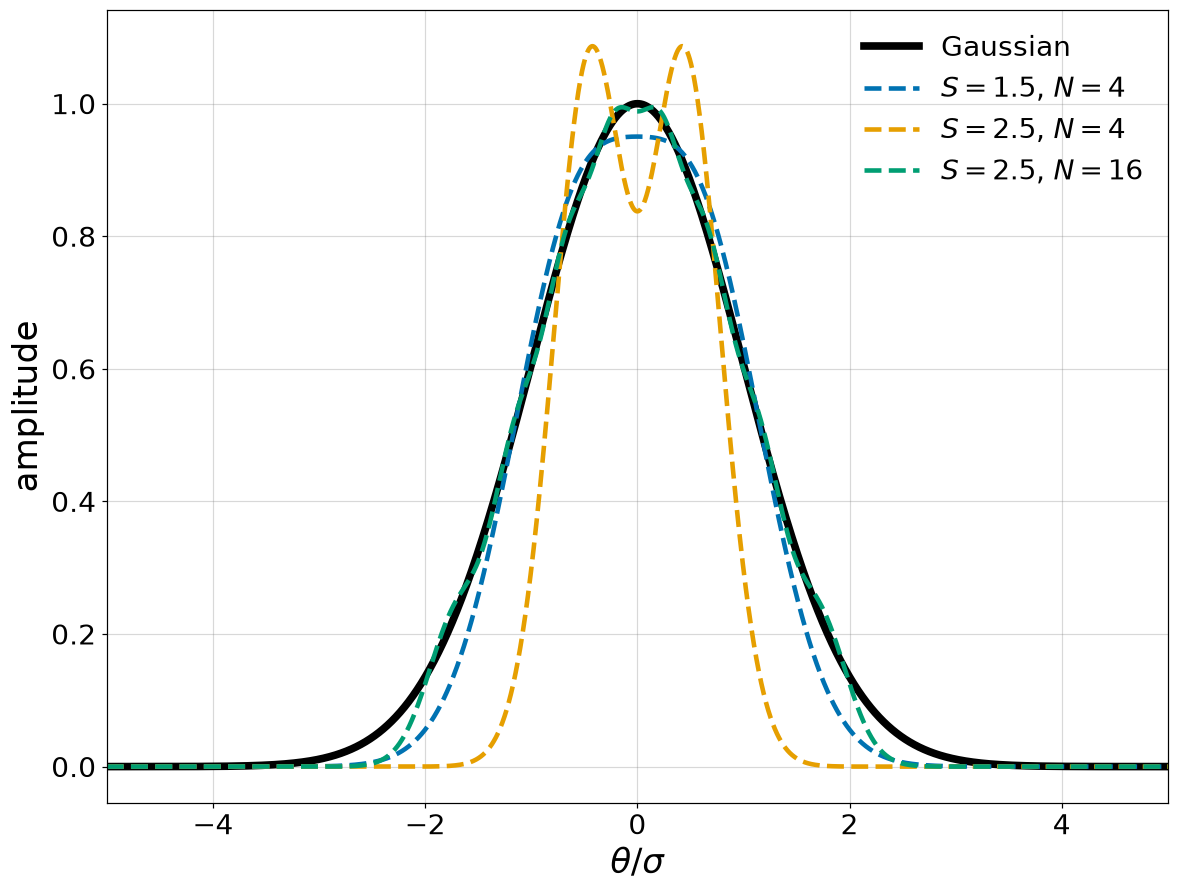

relative L2 errors (not on the slide): {(1.5, 4): np.float64(0.093), (2.5, 4): np.float64(0.3599), (2.5, 16): np.float64(0.0393)}


In [2]:
fits = [(1.5, 4), (2.5, 4), (2.5, 16)]           # (S = sigma/W, N); S = 2.5 is W/sigma = 0.4
fit_colours = ["#0072B2", "#E69F00", "#009E73"]  # Okabe-Ito blue, orange, green
fig, ax = plt.subplots()
target = project(1.0, 1)[0]
ax.plot(theta, target, color="k", lw=5, label="Gaussian")
for (s, n_basis), colour in zip(fits, fit_colours):
    ax.plot(theta, project(1 / s, n_basis)[1], color=colour, ls="--", lw=3, label=rf"$S = {s:g}$, $N = {n_basis}$")
ax.set(xlim=(-5, 5), xlabel=r"$\theta/\sigma$", ylabel="amplitude")
ax.legend(loc="upper right")
fig.savefig(plots_dir / "fig_slide11_gaussian_fits.png")
plt.show()
print("relative L2 errors (not on the slide):", {(s, n_basis): round(project(1 / s, n_basis)[2], 4) for s, n_basis in fits})

## Slide-12 table check: $N$ for a 1% relative $L^2$ error

Exact error (Tang 1993 Eq. 3.14 summed in closed form, as `kbm_width_ushape.ipynb`), with $S = \sigma/W$ (as slide 11) and
$r = (S^2-1)/(S^2+1)$: $\epsilon_N(S) = [1 - \sqrt{1-r^2}\sum_{k<\lceil N/2\rceil}\binom{2k}{k}(r^2/4)^k]^{1/2}$, checked against the
numerical projection above. The coefficient-decay estimate is $2\ln(100)/\ln|(S^2+1)/(S^2-1)|$ (the slide's original column). The error depends on $S$ only through $r^2$, so it is the same
for $S$ and $1/S$: the table is unchanged by writing it in $S = \sigma/W$ rather than $W/\sigma$ (the assert below checks it on
the projection with $W/\sigma = 1/S$).

In [3]:
def gaussian_error(s, n_basis):
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    kept = sum(comb(2 * k, k) * (r_squared / 4) ** k for k in range((n_basis + 1) // 2))
    return np.sqrt(max(1 - np.sqrt(1 - r_squared) * kept, 0))


for s in (1, 1.5, 2, 3):
    n_needed = next(n for n in range(1, 200) if gaussian_error(s, n) <= 0.01)
    assert abs(gaussian_error(s, n_needed) - project(1 / s, n_needed)[2]) < 1e-6    # closed form = numerical projection, W/sigma = 1/S
    estimate = "-" if s == 1 else f"{2 * np.log(100) / np.log(abs((s ** 2 + 1) / (s ** 2 - 1))):.1f}"
    print(f"S = {s}: N(1% L2) = {n_needed} (error {gaussian_error(s, n_needed):.4f}), coefficient-decay estimate {estimate}")

S = 1: N(1% L2) = 1 (error 0.0000), coefficient-decay estimate -
S = 1.5: N(1% L2) = 9 (error 0.0043), coefficient-decay estimate 9.6
S = 2: N(1% L2) = 15 (error 0.0082), coefficient-decay estimate 18.0
S = 3: N(1% L2) = 35 (error 0.0083), coefficient-decay estimate 41.3
